<a href="https://colab.research.google.com/github/MoisesNb7/indicadores_felicidad_analisis/blob/main/indicadores_felicidad_analisis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**TRAYECTORIA:** *Data Scientist*

**SUBCOMPETENCIA:** Visualización estática de datos

**RETO**: Explorando el índice de felicidad

---

*   NOMBRE: Moises Navarrete Bautista

---

# Exploración y Dinámica del Bienestar: Informe Mundial sobre la Felicidad

Investigación exploratoria sobre cómo se comportan los indicadores de bienestar y la evolución del posicionamiento de México a partir de `happiness_report.csv`, examinando el puntaje general (`score`), los seis factores explicativos (*GDP per capita*, *Healthy life expectancy*, *Social support*, *Freedom to make life choices*, *Generosity* y *Perceptions of corruption*) y el componente *Dystopia + residual*.

## Propósito de la investigación
- Examinar la estructura de las variables y el comportamiento general del conjunto de datos[cite: 1].
- Aislar y estructurar la serie histórica correspondiente a México indexando por `Year` para facilitar el seguimiento temporal[cite: 1].
- Contrastar relaciones y trayectorias mediante gráficas individuales, superpuestas y multi-panel (*subplots*) con enfoque de lectura analítica[cite: 1].

## Recorrido del análisis
1. Inspección inicial y carga del dataset (`happiness`) desde `happiness_report.csv`[cite: 1].
2. Construcción del subconjunto enfocado en México (`mexico`) con `Year` como índice temporal[cite: 1].
3. Análisis visual de tendencias y cambios en el *ranking* de felicidad de México a lo largo del tiempo[cite: 1].

In [ ]:
# Importar las bibliotecas necesarias
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

1.	Lee el archivo happiness_report.csv para guardar, en un *dataframe* (`happiness`), todos sus registros.

In [ ]:
happiness = pd.read_csv('happiness_report.csv')
happiness

,Year,Rank,Country name,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Dystopia + residual
0,2024,1,Finland,7.736,1.749,1.783,0.824,0.986,0.110,0.502,1.782
1,2023,143,Afghanistan,1.721,0.628,0.000,0.242,0.000,0.091,0.088,0.672
2,2022,137,Afghanistan,1.859,0.645,0.000,0.087,0.000,0.093,0.059,0.976
3,2021,146,Afghanistan,2.404,0.758,0.000,0.289,0.000,0.089,0.005,1.263
4,2020,150,Afghanistan,2.523,0.370,0.000,0.126,0.000,0.122,0.010,1.895
...,...,...,...,...,...,...,...,...,...,...,...
1964,2016,138,Zimbabwe,3.875,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1965,2015,131,Zimbabwe,4.193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1966,2014,115,Zimbabwe,4.610,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1967,2012,103,Zimbabwe,4.827,NaN,NaN,NaN,NaN,NaN,NaN,NaN


2. A partir del *dataframe* `happiness` obtén otro (`mexico`) donde únicamente almacenes la información de México. Haz que la columna `Year` quede como índice.

In [ ]:
mexico = happiness[happiness['Country name'] == 'Mexico'].set_index('Year')
mexico

,Rank,Country name,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Dystopia + residual
Year,,,,,,,,,,
2024,10,Mexico,6.979,1.435,1.504,0.550,0.879,0.057,0.118,2.438
2023,25,Mexico,6.678,1.521,1.241,0.544,0.722,0.086,0.127,2.437
2022,36,Mexico,6.330,1.550,1.169,0.389,0.632,0.086,0.115,2.389
2021,46,Mexico,6.128,1.552,0.886,0.623,0.621,0.092,0.115,2.239
2020,37,Mexico,6.317,1.126,0.830,0.634,0.585,0.092,0.089,2.961
2019,24,Mexico,6.465,1.024,1.226,0.832,0.554,0.083,0.083,2.663
2018,23,Mexico,6.595,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017,24,Mexico,6.488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016,25,Mexico,6.578,NaN,NaN,NaN,NaN,NaN,NaN,NaN


3. Obtén un gráfico de línea que muestre cómo ha cambiado el lugar de México en el *ranking* de felicidad a través de los años. Asegúrate de personalizarlo de acuerdo con el formato mostrado en la figura de referencia.

Text(0.5, 1.0, 'Mexico Happiness Ranking')

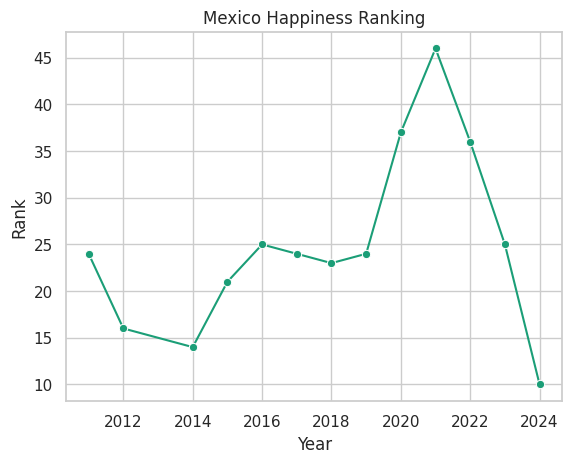

In [ ]:
sns.set_theme(style="whitegrid", palette="Dark2")
sns.lineplot(x=mexico.index, y=mexico['Rank'], marker='o')
plt.title('Mexico Happiness Ranking')

4. Utiliza la información del 2024 del *dataframe* `mexico` para analizar en qué medida los factores contribuyen a evaluar la felicidad, a través de un gráfico circular.

/tmp/ipykernel_1203/328720547.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  mexico_2024.plot.pie(y='Score', autopct='%1.1f%%', ylabel='' )


Text(0.5, 1.0, 'Contribution of Factors - Mexico Score (2024)')

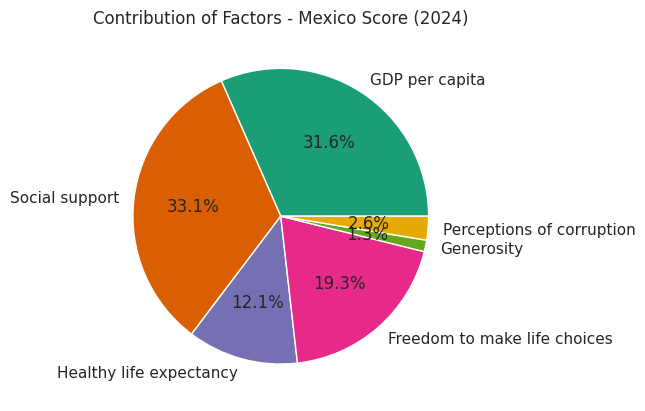

In [ ]:
mexico_2024 = mexico.loc[2024].drop(['Rank', 'Country name','Score','Dystopia + residual'])
mexico_2024.plot.pie(y='Score', autopct='%1.1f%%', ylabel='' )
plt.title("Contribution of Factors - Mexico Score (2024)")


5. Filtra el *dataframe* `happiness` para quedarte con la información del 2024 de todos los países (`report2024`). Genera un gráfico de barras para comparar el `Score` del país con mayor felicidad, el de menor puntuación, México y dos economías emergentes similares: Brasil e Indonesia. Incluye el promedio global con una línea horizontal.

5.578170068027211
5.638


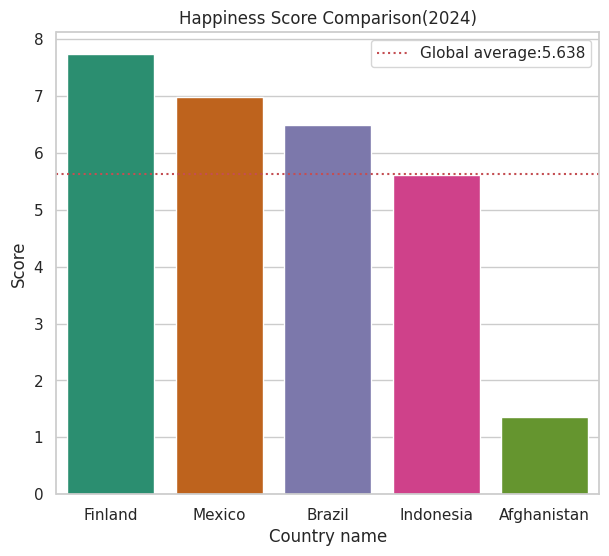

In [ ]:
report2024 = happiness[happiness['Year'] == 2024]
report2024_mean = report2024['Score'].mean() # promedio global

#max = report2024.loc[report2024["Score"].idxmax()]
#min = report2024.loc[report2024["Score"].idxmin()]
print(report2024_mean)
#print(max)
#print(min)
report2024 = report2024[report2024['Country name'].isin(['Finland','Mexico', 'Brazil','Indonesia', 'Afghanistan'])][["Country name", "Score"]]
report2024_mean = report2024['Score'].mean() #promedio de los paises


#max = report2024.loc[report2024["Score"].idxmax()]
#min = report2024.loc[report2024["Score"].idxmin()]
print(report2024_mean)
sns.set_theme(style="whitegrid")
plt.figure(figsize=(7, 6))

sns.barplot(
    data=report2024,
    x="Country name",
    y="Score",
    hue="Country name",
    palette="Dark2",
    legend=False,

)
plt.axhline(y=report2024_mean, color='r', linestyle=':', label=f'Global average:{report2024_mean:.3f}')
plt.title('Happiness Score Comparison(2024)')
plt.legend()


6. Para analizar el impacto de la pandemia en los niveles de felicidad, elabora un gráfico con histogramas superpuestos, correspondientes a los años 2020 y 2024.

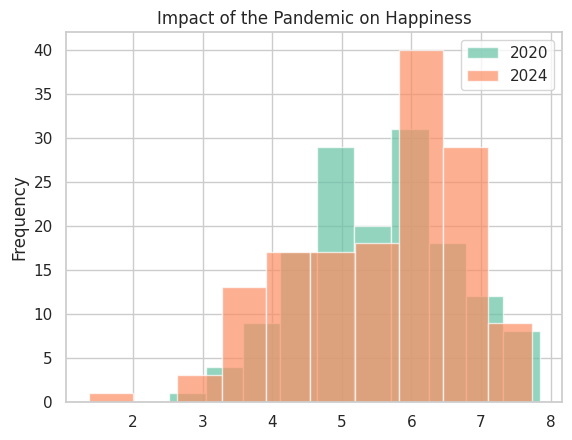

In [ ]:
happiness_2020 = happiness[happiness['Year'] == 2020]
happiness_2024 = happiness[happiness['Year'] == 2024]
colors = sns.color_palette("Set2")
happiness_2020['Score'].plot.hist(alpha=0.7, label='2020', color= colors[0],edgecolor='white')
happiness_2024['Score'].plot.hist(alpha=0.7, label='2024', color= colors[1], edgecolor='white')
plt.title('Impact of the Pandemic on Happiness')
plt.legend()
plt.show()

7. En una misma figura, traza *boxplots* que ilustren la dispersión de los seis factores explicativos de la felicidad en el año 2024.

([0, 1, 2, 3, 4, 5],
 [Text(0, 0, 'GDP per capita'),
  Text(1, 0, 'Social support'),
  Text(2, 0, 'Healthy life expectancy'),
  Text(3, 0, 'Freedom to make life choices'),
  Text(4, 0, 'Generosity'),
  Text(5, 0, 'Perceptions of corruption')])

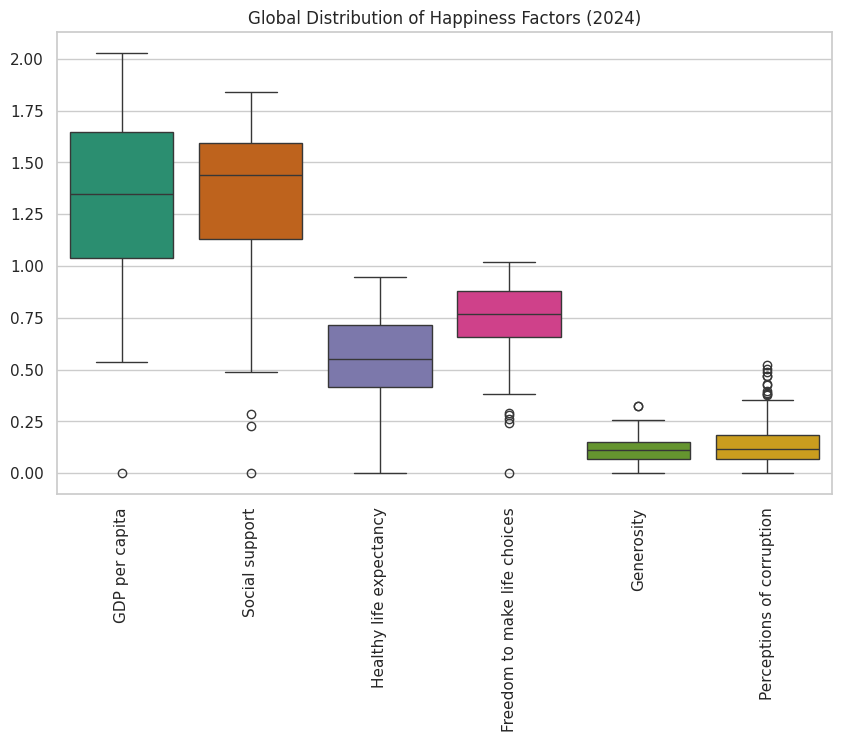

In [ ]:
factores = [
    "GDP per capita",
    "Social support",
    "Healthy life expectancy",
    "Freedom to make life choices",
    "Generosity",
    "Perceptions of corruption",
]
plt.figure(figsize=(10, 6))

happiness_2024_factores = happiness_2024[factores]
sns.boxplot(data=happiness_2024_factores, palette="Dark2")
plt.title('Global Distribution of Happiness Factors (2024)')
plt.xticks(rotation=90)


8. Crea una matriz de subgráficas de 2 x 3 con *scatter plots* del `Score` versus los seis factores, para determinar qué factor influye más en la felicidad. Configura los ejes para que las marcas del eje `x` se compartan por columna, mientras que cada subgráfica conserve su propio eje `y`.

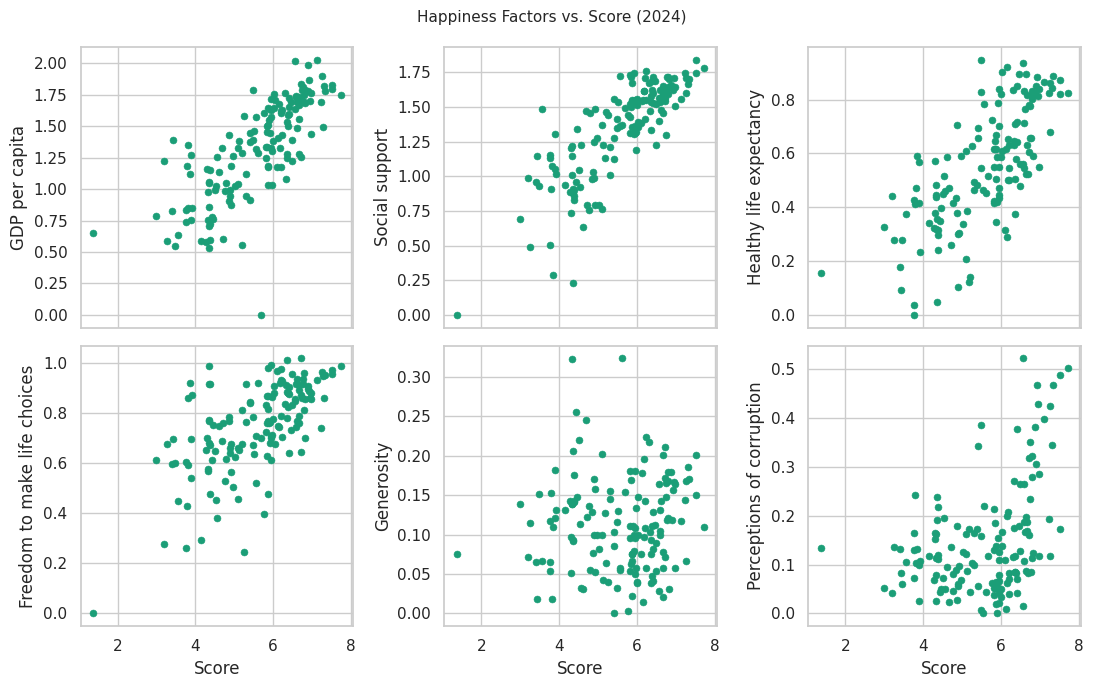

In [ ]:
sns.set_theme(style="whitegrid")
fig = plt.figure(figsize=(11, 7))
fig.suptitle("Happiness Factors vs. Score (2024)", fontsize=11)
verde = sns.color_palette("Dark2")[0]

# --- FILA 1 ---
ax1 = fig.add_subplot(231)
sns.scatterplot(
    data=happiness_2024, x="Score", y="GDP per capita", color=verde,
    edgecolor=None, s=25, ax=ax1
)
ax1.set_xlabel("")

ax2 = fig.add_subplot(232)
sns.scatterplot(
    data=happiness_2024, x="Score", y="Social support", color=verde,
    edgecolor=None, s=25, ax=ax2
)
ax2.set_xlabel("")

ax3 = fig.add_subplot(233)
sns.scatterplot(
    data=happiness_2024,
    x="Score",
    y="Healthy life expectancy",
    color=verde,
    edgecolor=None,
    s=25,
    ax=ax3,
)
ax3.set_xlabel("")

# --- FILA 2 ---
ax4 = fig.add_subplot(234)
sns.scatterplot(
    data=happiness_2024,
    x="Score",
    y="Freedom to make life choices",
    color=verde,
    edgecolor=None,
    s=25,
    ax=ax4,
)

ax5 = fig.add_subplot(235)
sns.scatterplot(
    data=happiness_2024, x="Score", y="Generosity", color=verde,
    edgecolor=None, s=25, ax=ax5
)

ax6 = fig.add_subplot(236)
sns.scatterplot(
    data=happiness_2024,
    x="Score",
    y="Perceptions of corruption",
    color=verde,
    edgecolor=None,
    s=25,
    ax=ax6,
)
plt.setp(ax1.get_xticklabels(), visible=False)
plt.setp(ax2.get_xticklabels(), visible=False)
plt.setp(ax3.get_xticklabels(), visible=False)

ax1.set_xlabel("")
ax2.set_xlabel("")
ax3.set_xlabel("")

plt.tight_layout()
plt.show()

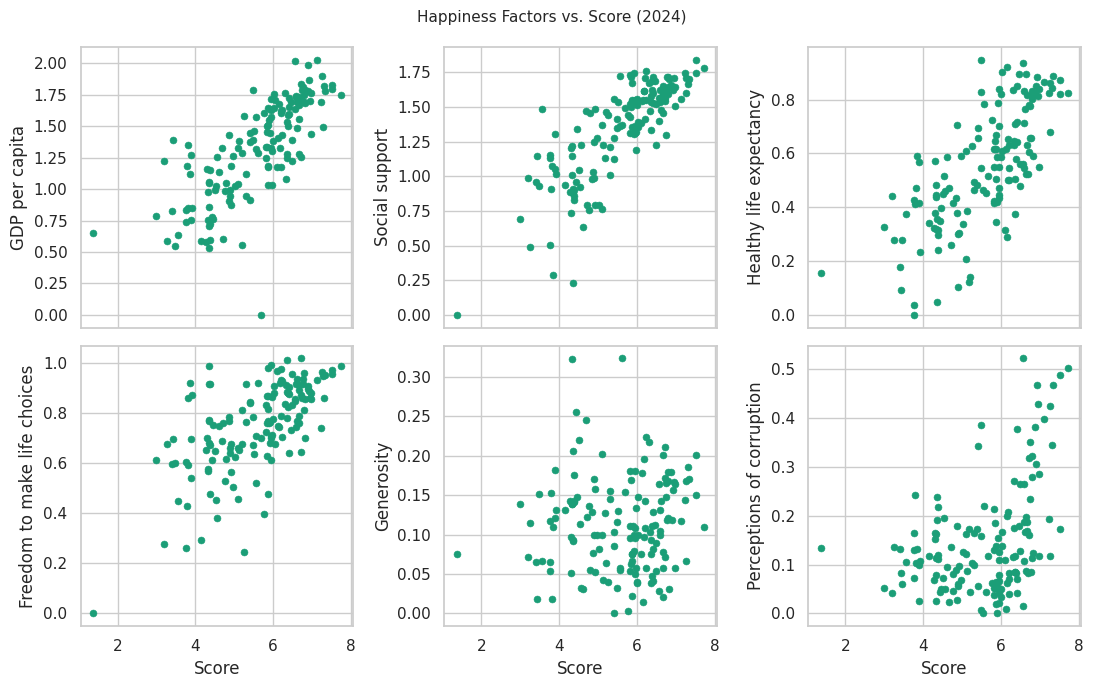

In [ ]:
sns.set_theme(style="whitegrid")
verde = sns.color_palette("Dark2")[0]

variables_y = [
    "GDP per capita", "Social support", "Healthy life expectancy",
    "Freedom to make life choices", "Generosity", "Perceptions of corruption"
]

fig, axes = plt.subplots(2, 3, figsize=(11, 7), sharex=True)
fig.suptitle("Happiness Factors vs. Score (2024)", fontsize=11)

for ax, col in zip(axes.flat, variables_y):
    sns.scatterplot(
        data=happiness_2024, x="Score", y=col,
        color=verde, edgecolor=None, s=25, ax=ax
    )

plt.tight_layout()
plt.show()

9. Comprueba lo anterior con un mapa de calor donde incluyas los índices de correlación.

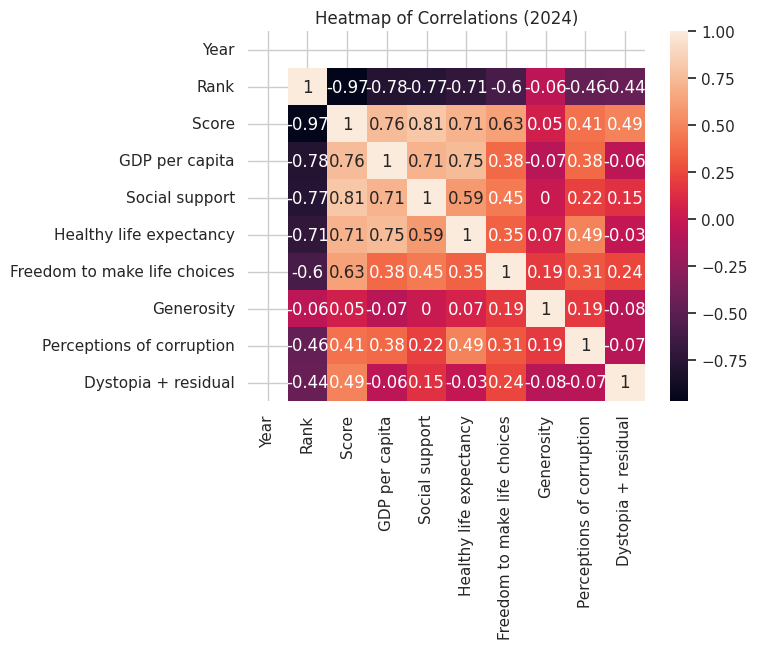

In [ ]:
sns.heatmap(round(happiness_2024.corr(numeric_only=True),2),annot=True)
plt.title("Heatmap of Correlations (2024)")
plt.show()

10. Utiliza un gráfico de densidad y contorno para representar la relación entre el PIB per cápita y la esperanza de vida saludable. Señala la posición de México mediante una anotación, procurando que el resultado final mantenga una apariencia similar a la imagen correspondiente.

1.435 0.55


Text(0, 1.02, 'MEX')

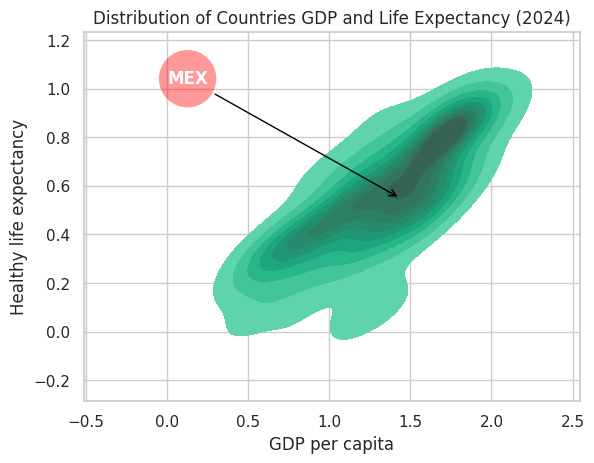

In [ ]:
sns.kdeplot(
    data=happiness_2024,
    x="GDP per capita",
    y="Healthy life expectancy", fill=True, color=verde)
plt.xlabel("GDP per capita")
plt.ylabel("Healthy life expectancy")
plt.title("Distribution of Countries GDP and Life Expectancy (2024)")

coordenadas_mexico = (mexico_2024['GDP per capita'], mexico_2024['Healthy life expectancy'])
coordenadas_mexico

print(mexico_2024['GDP per capita'], mexico_2024['Healthy life expectancy'])

props_bbox = dict(
    boxstyle="circle,pad=0.5",
    facecolor="red",

    alpha=0.4,
    edgecolor="none",
)

plt.annotate('MEX',xy=(1.435,0.55),xytext=(0,1.02), bbox=props_bbox, color="white", fontweight="bold",
arrowprops=dict(arrowstyle='->',color='BLACK'))